# Lezione 10 — Notebook Docente
## Caso TakeHome: Lehman Brothers 2008

Soluzione di riferimento coerente con la Scheda Caso TakeHome.

- $N_{\mathrm{MC}}=50\,000$;
- seed $2026$;
- $T=4$ trimestri;
- misura fisica;
- una traiettoria sistemica comune per replica;
- stesse traiettorie creditizie per i 39 debitori comuni.

## 1. Import e CVaR empirico

Il CVaR è implementato mediante
$$
\operatorname{CVaR}_{\alpha}(L)=\frac{1}{1-\alpha}\int_{\alpha}^1 q_u(L)\,du.
$$

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def empirical_var(x, alpha):
    xs=np.sort(np.asarray(x,float)); n=len(xs)
    return xs[max(0, math.ceil(alpha*n)-1)]

def empirical_cvar(x, alpha):
    xs=np.sort(np.asarray(x,float)); n=len(xs); a=alpha*n; k=int(np.floor(a))
    if np.isclose(a,k):
        integ=xs[k:].sum()/n
    else:
        integ=((k+1)/n-alpha)*xs[k] + xs[k+1:].sum()/n
    return integ/(1-alpha)

def risk_summary(x):
    x=np.asarray(x,float)
    return {
      "Perdita media":x.mean(),
      "Varianza":x.var(ddof=0),
      "Deviazione standard":x.std(ddof=0),
      "VaR 95%":empirical_var(x,.95),
      "CVaR 95%":empirical_cvar(x,.95),
      "VaR 99%":empirical_var(x,.99),
      "CVaR 99%":empirical_cvar(x,.99)}

## 2. Parametri e controlli preliminari

In [2]:
N_MC=50_000; SEED=2026; T=4
sys_states=np.array(["O","S","C"]); cred_states=np.array(["A","BBB","BB","B","D"])
si={s:i for i,s in enumerate(sys_states)}; ci={s:i for i,s in enumerate(cred_states)}

Q=np.array([[.82,.16,.02],[.30,.55,.15],[.10,.35,.55]])
P={
"O":np.array([[.960,.035,.004,.0005,.0005],[.020,.940,.030,.007,.003],[.004,.030,.910,.046,.010],[.001,.004,.025,.940,.030],[0,0,0,0,1.]]),
"S":np.array([[.920,.060,.014,.004,.002],[.010,.870,.085,.027,.008],[.002,.018,.820,.135,.025],[0,.002,.018,.880,.100],[0,0,0,0,1.]]),
"C":np.array([[.820,.120,.040,.015,.005],[.005,.760,.150,.060,.025],[0,.010,.680,.230,.080],[0,.001,.009,.740,.250],[0,0,0,0,1.]])}
phi=np.array([[0,.03,.10,.22,.65],[-.02,0,.06,.16,.65],[-.04,-.02,0,.09,.65],[-.06,-.04,-.02,0,.65]])
assert np.allclose(Q.sum(1),1)
for A in P.values():
    assert np.allclose(A.sum(1),1) and np.allclose(A[-1],[0,0,0,0,1])
print("Matrici: OK")

Matrici: OK


## 3. Portafogli

In [3]:
ratings_lbl=["A"]+["A"]*11+["BBB"]*14+["BB"]*9+["B"]*5
r0=np.array([ci[x] for x in ratings_lbl])
V0=np.array([25.]+[5.]*11+[4.]*14+[3.]*9+[2.]*5)
res=np.arange(1,40)
V1=V0[res]*(173/148)
assert len(V0)==40 and np.isclose(V0.sum(),173)
assert len(V1)==39 and np.isclose(V1.sum(),173)
assert np.allclose(V1/V0[res],173/148)
print("Totale concentrato:",V0.sum())
print("Totale controfattuale:",V1.sum())

Totale concentrato: 173.0
Totale controfattuale: 172.99999999999997


## 4. Simulazione delle traiettorie

In [4]:
rng=np.random.default_rng(SEED); n=len(r0)
M=np.empty((N_MC,T),np.int8); X=np.empty((N_MC,T+1,n),np.int8)
M[:,0]=si["S"]; X[:,0,:]=r0

def draw_rows(prob,u):
    return (u[:,None] > np.cumsum(prob,axis=1)).sum(1)

for t in range(T):
    cur=X[:,t,:]; nxt=cur.copy()
    for lab,mcode in si.items():
        rows=np.where(M[:,t]==mcode)[0]
        if not len(rows): continue
        A=P[lab]
        for j in range(n):
            st=cur[rows,j]
            nxt[rows,j]=draw_rows(A[st],rng.random(len(rows)))
    X[:,t+1,:]=nxt
    if t<T-1: M[:,t+1]=draw_rows(Q[M[:,t]],rng.random(N_MC))
D=ci["D"]
for t in range(T):
    m=X[:,t,:]==D
    assert np.all(X[:,t+1,:][m]==D)
print("Traiettorie simulate:",X.shape)

Traiettorie simulate: (50000, 5, 40)


## 5. Perdite individuali e di portafoglio

La funzione di perdita è
$$
L_i=V_{i,0}\varphi(X_{i,0},X_{i,4}),
$$
con $\varphi(r_0,D)=0.65$. Poiché la LGD è costante e \(D\) è assorbente, non serve il trimestre del primo default per determinare la perdita monetaria.

In [5]:
fin=X[:,-1,:]
lr=np.empty((N_MC,n))
for j in range(n):
    lr[:,j]=phi[r0[j],fin[:,j]]
Li0=lr*V0
L0=Li0.sum(1)
Li1=lr[:,res]*V1
L1=Li1.sum(1)
dL=L1-L0
assert np.allclose(L0,Li0.sum(1)) and np.allclose(L1,Li1.sum(1))
print("Perdite costruite: OK")

Perdite costruite: OK


## 6. Misure di rischio e analisi del regime sistemico

In [6]:
R0=risk_summary(L0); R1=risk_summary(L1)
tab=pd.DataFrame({"Concentrato":R0,"Controfattuale":R1}); tab["Differenza"]=tab["Controfattuale"]-tab["Concentrato"]
crisis=np.any(M==si["C"],axis=1)
display(tab)
display(pd.DataFrame({
"Quantità":["P(ingresso in C)","E[L conc|C]","E[L conc|no C]","E[Delta L]","P(Delta L>0)"],
"Valore":[crisis.mean(),L0[crisis].mean(),L0[~crisis].mean(),dL.mean(),(dL>0).mean()]}))

,Concentrato,Controfattuale,Differenza
Perdita media,11.1549,12.2277,1.0728
Varianza,48.1908,53.3411,5.1502
Deviazione standard,6.9420,7.3035,0.3615
VaR 95%,24.8600,26.6747,1.8147
CVaR 95%,29.6854,31.0117,1.3263
VaR 99%,32.7000,33.6999,0.9999
CVaR 99%,37.0938,37.0101,-0.0837


,Quantità,Valore
0,P(ingresso in C),0.2975
1,E[L conc|C],18.3150
2,E[L conc|no C],8.1224
3,E[Delta L],1.0728
4,P(Delta L>0),0.8971


## 7. Tabelle di portafoglio

In [7]:
display(pd.DataFrame({
"Gruppo":["Lehman Brothers","Altri A","BBB","BB","B"],
"N":[1,11,14,9,5],
"Rating":["A","A","BBB","BB","B"],
"V per debitore":[25,5,4,3,2],
"V complessivo":[25,55,56,27,10]}))
f=173/148
display(pd.DataFrame({
"Gruppo":["Altri A","BBB","BB","B"],
"N":[11,14,9,5],
"Rating":["A","BBB","BB","B"],
"V per debitore":[5*f,4*f,3*f,2*f],
"V complessivo":[55*f,56*f,27*f,10*f]}))

,Gruppo,N,Rating,V per debitore,V complessivo
0,Lehman Brothers,1,A,25,25
1,Altri A,11,A,5,55
2,BBB,14,BBB,4,56
3,BB,9,BB,3,27
4,B,5,B,2,10


,Gruppo,N,Rating,V per debitore,V complessivo
0,Altri A,11,A,5.8446,64.2905
1,BBB,14,BBB,4.6757,65.4595
2,BB,9,BB,3.5068,31.5608
3,B,5,B,2.3378,11.6892


## 8. Grafici richiesti

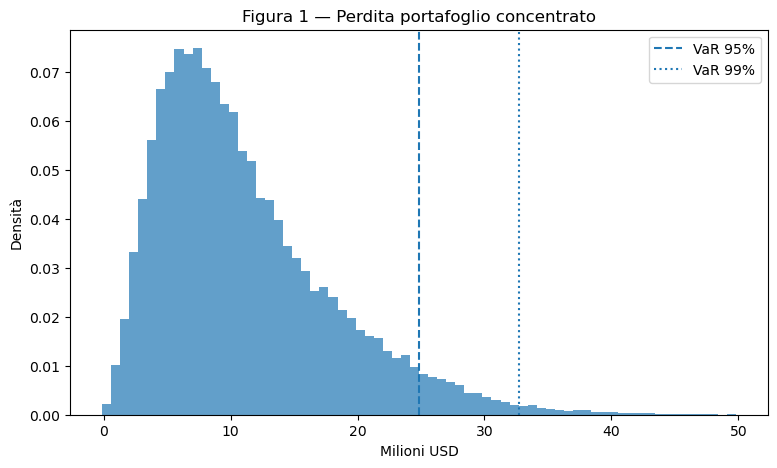

In [8]:
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(L0,bins=70,density=True,alpha=.7)
ax.axvline(R0["VaR 95%"],ls="--",label="VaR 95%"); ax.axvline(R0["VaR 99%"],ls=":",label="VaR 99%")
ax.set(title="Figura 1 — Perdita portafoglio concentrato",xlabel="Milioni USD",ylabel="Densità"); ax.legend(); plt.show()

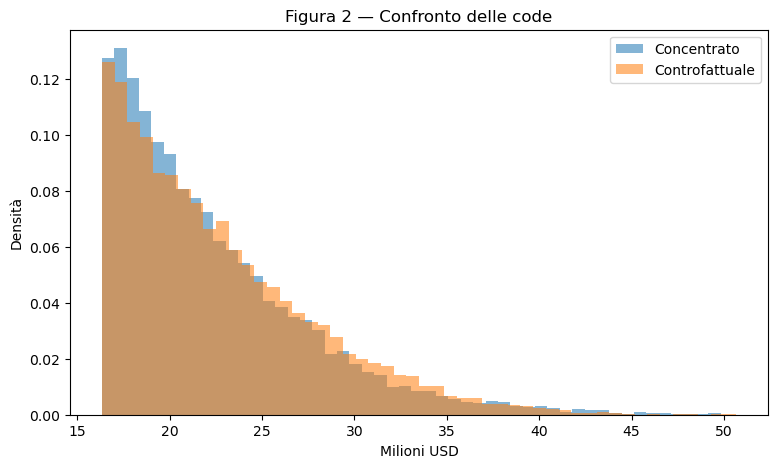

In [9]:
q80=min(np.quantile(L0,.80),np.quantile(L1,.80))
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(L0[L0>=q80],bins=50,density=True,alpha=.55,label="Concentrato")
ax.hist(L1[L1>=q80],bins=50,density=True,alpha=.55,label="Controfattuale")
ax.set(title="Figura 2 — Confronto delle code",xlabel="Milioni USD",ylabel="Densità"); ax.legend(); plt.show()

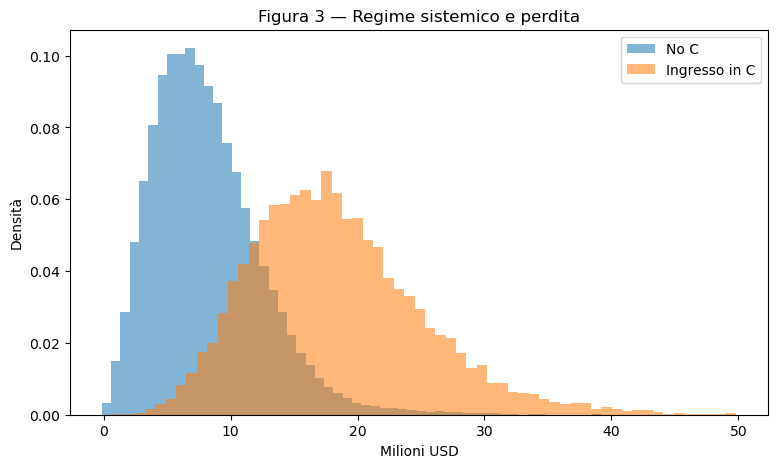

In [10]:
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(L0[~crisis],bins=60,density=True,alpha=.55,label="No C")
ax.hist(L0[crisis],bins=60,density=True,alpha=.55,label="Ingresso in C")
ax.set(title="Figura 3 — Regime sistemico e perdita",xlabel="Milioni USD",ylabel="Densità"); ax.legend(); plt.show()

## 9. Stabilità Monte Carlo

In [11]:
display(pd.DataFrame({
"Conc 50k":risk_summary(L0),"Conc 25k":risk_summary(L0[:25000]),
"Div 50k":risk_summary(L1),"Div 25k":risk_summary(L1[:25000])}))

,Conc 50k,Conc 25k,Div 50k,Div 25k
Perdita media,11.1549,11.1563,12.2277,12.2261
Varianza,48.1908,48.1619,53.3411,53.5027
Deviazione standard,6.9420,6.9399,7.3035,7.3146
VaR 95%,24.8600,24.7200,26.6747,26.6864
CVaR 95%,29.6854,29.6005,31.0117,31.0090
VaR 99%,32.7000,32.5600,33.6999,33.7818
CVaR 99%,37.0938,37.1296,37.0101,36.9744


## 10. Chiusura docente

Controlli coperti: matrici stocastiche, default assorbente, domini degli stati, dimensioni dei portafogli, investimento totale, conservazione delle proporzioni, riconciliazione perdite, seed, VaR/CVaR, stabilità.

Proprietà **PER COSTRUZIONE**: una traiettoria sistemica per replica, estrazioni individuali condizionate al regime, stesse traiettorie creditizie per i 39 debitori comuni.

Interpretazione: il controfattuale non identifica un effetto puro della sola concentrazione, perché la riallocazione modifica anche la composizione per rating.